# Tweet Sentiment Classification with Hand-Built Features

A from-scratch linear SVM text classifier for positive/negative tweets (~27k labelled tweets, 80/20 split): tokenisation and normalisation, bag-of-words and n-gram features, 10-fold cross-validation, systematic error analysis of false positives and negatives, then optimised pre-processing and feature extraction.


In [1]:
import csv                               # csv reader
from sklearn.svm import LinearSVC
from nltk.classify import SklearnClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_fscore_support # to report on precision and recall
import numpy as np
import re # for regular expressions

#### Adding seed for reproducibility

In [2]:
import random
random.seed(1905)

In [3]:
def load_data(path):
    """Load data from a tab-separated file and append it to raw_data."""
    with open(path) as f:
        reader = csv.reader(f, delimiter='\t')
        for line in reader:
            if line[0] == "Id":  # skip header
                continue
            (label, text) = parse_data_line(line)
            raw_data.append((text, label))

def split_and_preprocess_data(percentage):
    """Split the data between train_data and test_data according to the percentage
    and performs the preprocessing."""
    num_samples = len(raw_data)
    num_training_samples = int((percentage * num_samples))
    for (text, label) in raw_data[:num_training_samples]:
        train_data.append((to_feature_vector(pre_process(text)),label))
    for (text, label) in raw_data[num_training_samples:]:
        test_data.append((to_feature_vector(pre_process(text)),label))

# Part 1: Input and Basic preprocessing

In [4]:
def parse_data_line(data_line):
    # Should return a tuple of the label as just positive or negative and the statement
    # e.g. (label, statement)
    return (data_line[1], data_line[2])

#### commented out lines are not chosen for the best performing model that is applied to the test dataset later on

In [5]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words("english"))
from nltk.stem import PorterStemmer,WordNetLemmatizer
# Initialize the stemmer
stemmer = PorterStemmer()
from nltk.util import ngrams
lemmatizer = WordNetLemmatizer()

def pre_process(text):
    """ it preprocesses the input text by lowercasing it first, then splitting it
    """
    ## Basic Preprocessing
    # lowercase the text
    text = text.lower()

    # punctuation removal and removing non alphabetical characters
    text = re.sub(r'[^a-z\s]', '', text)
    
    ## Also Basic Preprocessing
    # tokenize by splitting on whitespace
    tokens = text.split()

    # # stop word removal
    # tokens = [word for word in tokens if word not in stop_words]


    # # lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # # #bigrams
    bigrams = ['_'.join(bigram) for bigram in ngrams(tokens, 2)]
    # # # # Combine unigrams and bigrams
    tokens += bigrams


    # # # trigrams
    # trigrams = ['_'.join(trigrams) for trigrams in ngrams(tokens, 3)]
    # # Combine unigrams, bigrams, and trigrams
    # tokens += bigrams + trigrams
    
    return tokens 


# Part 2: Basic Feature Extraction

In [ ]:
from collections import Counter

global_feature_dict = {}  # Global dictionary of features

def to_feature_vector(tokens,n=300):
    """
    converts a list of tokens into a feature vector using bag of words approach
    """
    # Basic approach
    feature_vector = Counter(tokens)  # bag of words approach

    # # adding sentence length as a feature
    # feature_vector["sentence_length"] = len(tokens)

    # updating the global word count dictionary
    for token in feature_vector:
        global_feature_dict[token] = global_feature_dict.get(token, 0) + 1
    
    return feature_vector

In [7]:
# TRAINING AND VALIDATING OUR CLASSIFIER

def train_classifier(data):
    """
    trains svm on the input and returns the model from the pipeline
    """
    print("Training Classifier...")
    pipeline =  Pipeline([('svc', LinearSVC())])
    return SklearnClassifier(pipeline).train(data)

# Part 3: Cross-validation

In [ ]:
def cross_validate(dataset, folds=10, perform_error_analysis=False):
    results = []  # Store metrics for each fold
    fold_size = int(len(dataset) / folds) + 1  # Calculate the size of each fold

    # Variables to store the last fold's data for error analysis if needed
    last_fold_true_labels = []
    last_fold_predicted_labels = []
    last_fold_test_data = []

    for i in range(0, len(dataset), fold_size):
        # Determine the test and training data for this fold
        test_data = dataset[i:i + fold_size]
        train_data = dataset[:i] + dataset[i + fold_size:]

        print(f"Fold start on items {i} - {i + fold_size}")

        # training starts
        classifier = train_classifier(train_data)

        # label prediction
        test_features = [features for features, label in test_data]
        true_labels = [label for features, label in test_data]
        predicted_labels = predict_labels(test_features, classifier)

        # store metrics for this fold
        metrics = calculate_metrics(true_labels, predicted_labels)
        results.append(metrics)

        # save data for the last fold if error analysis is enabled
        if i + fold_size >= len(dataset):
            last_fold_true_labels = true_labels
            last_fold_predicted_labels = predicted_labels
            last_fold_test_data = test_data

    # calculate and print average metrics for all folds by using the below func
    avg_results = calculate_average_metrics(results)
    print("\nCross-Validation Results:")
    print(f"Average Precision: {avg_results['precision']:.4f}")
    print(f"Average Recall: {avg_results['recall']:.4f}")
    print(f"Average F1-Score: {avg_results['f1']:.4f}")
    print(f"Average Accuracy: {avg_results['accuracy']:.4f}")

    # return data for error analysis if enabled
    if perform_error_analysis:
        return avg_results, last_fold_true_labels, last_fold_predicted_labels, last_fold_test_data
    else:
        return avg_results


In [ ]:
# PREDICTING LABELS GIVEN A CLASSIFIER
def predict_labels(samples, classifier):
    """Predict labels for a list of preprocessed feature vectors."""
    return classifier.classify_many(samples)

def predict_label_from_raw(sample, classifier):
    """Predict label for a single raw text sample after preprocessing."""
    return classifier.classify(to_feature_vector(pre_process(sample)))


#### the function to calculate the performance metrics

In [ ]:
from sklearn.metrics import accuracy_score

# function that takes true labels and predicted labels as an input and returns the precision, recall, f1 score and accuracy based on those inputs. 
# inside the function the metrics class from the sklearn library is used for ease of calculating performance metrics
def calculate_metrics(true_labels, predicted_labels):
    precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predicted_labels, average='binary', pos_label='positive')
    accuracy = accuracy_score(true_labels, predicted_labels)
    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy
    }


#### the function to calculate average metrics for each fold

In [ ]:
def calculate_average_metrics(results):
    avg_metrics = {
        "precision": sum(result["precision"] for result in results) / len(results),
        "recall": sum(result["recall"] for result in results) / len(results),
        "f1": sum(result["f1"] for result in results) / len(results),
        "accuracy": sum(result["accuracy"] for result in results) / len(results)
    }
    return avg_metrics


In [12]:
# MAIN

# loading reviews
# initialize global lists that will be appended to by the methods below
raw_data = []          # the filtered data from the dataset file
train_data = []        # the pre-processed training data as a percentage of the total dataset
test_data = []         # the pre-processed test data as a percentage of the total dataset


# references to the data files
data_file_path = 'sentiment-dataset.tsv'

# Do the actual stuff (i.e. call the functions we've made)
# We parse the dataset and put it in a raw data list
print("Now %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Preparing the dataset...",sep='\n')

load_data(data_file_path) 

# We split the raw dataset into a set of training data and a set of test data (80/20)
# You do the cross validation on the 80% (training data)
# We print the number of training samples and the number of features before the split
print("Now %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Preparing training and test data...",sep='\n')

split_and_preprocess_data(0.8)

# We print the number of training samples and the number of features after the split
print("After split, %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Training Samples: ", len(train_data), "Features: ", len(global_feature_dict), sep='\n')


Now 0 rawData, 0 trainData, 0 testData
Preparing the dataset...
Now 33540 rawData, 0 trainData, 0 testData
Preparing training and test data...
After split, 33540 rawData, 26832 trainData, 6708 testData
Training Samples: 
26832
Features: 
334588


In [13]:
cross_validate(train_data, 10)  # will work and output overall performance of p, r, f-score when cv implemented

Fold start on items 0 - 2684
Training Classifier...


Fold start on items 2684 - 5368
Training Classifier...


Fold start on items 5368 - 8052
Training Classifier...


Fold start on items 8052 - 10736
Training Classifier...


Fold start on items 10736 - 13420
Training Classifier...


...

Fold start on items 18788 - 21472
Training Classifier...


Fold start on items 21472 - 24156
Training Classifier...


Fold start on items 24156 - 26840
Training Classifier...



Cross-Validation Results:
Average Precision: 0.8791
Average Recall: 0.9186
Average F1-Score: 0.8984
Average Accuracy: 0.8661


{'precision': 0.8791267261798563,
 'recall': 0.9186244884394343,
 'f1': 0.898418105589419,
 'accuracy': 0.8660942105016941}

# Part 4: Error Analysis

In [14]:
from sklearn import metrics
import matplotlib.pyplot as plt
# a function to make the confusion matrix readable and pretty
def confusion_matrix_heatmap(y_test, preds, labels):
    """Function to plot a confusion matrix"""
    # pass labels to the confusion matrix function to ensure right order
    # cm = metrics.confusion_matrix(y_test, preds, labels)
    cm = metrics.confusion_matrix(y_test, preds, labels=labels)
    fig = plt.figure(figsize=(10,10))
    ax = fig.add_subplot(111)
    cax = ax.matshow(cm)
    plt.title('Confusion matrix of the classifier')
    fig.colorbar(cax)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels( labels, rotation=45)
    ax.set_yticklabels( labels)

    for i in range(len(cm)):
        for j in range(len(cm)):
            text = ax.text(j, i, cm[i, j],
                           ha="center", va="center", color="w")

    plt.xlabel('Predicted')
    plt.ylabel('True')
    
    # # fix for mpl bug that cuts off top/bottom of seaborn viz:
    # b, t = plt.ylim() # discover the values for bottom and top
    # b += 0.5 # Add 0.5 to the bottom
    # t -= 0.5 # Subtract 0.5 from the top
    # plt.ylim(b, t) # update the ylim(bottom, top) values
    plt.ylim(len(cm) - 0.5, -0.5)
    plt.show() # ta-da!
    plt.show()

In [ ]:
def error_analysis(test_data, true_labels, predicted_labels):
    """Perform error analysis by displaying false positives and false negatives and plotting confusion matrix. Also saving false negatives and false positives to two seperate files.
    
    Args:
        test_data (list): The test data (feature vectors and labels).
        true_labels (list): The true labels of the test set.
        predicted_labels (list): The predicted labels from the classifier.
    """
    false_positives = []
    false_negatives = []
    
    # Identify false positives and false negatives for the positive label
    for i, (true, pred) in enumerate(zip(true_labels, predicted_labels)):
        if true == 'negative' and pred == 'positive':
            false_positives.append(test_data[i])  # False positive
        elif true == 'positive' and pred == 'negative':
            false_negatives.append(test_data[i])  # False negative

    # Display the confusion matrix
    print("\nConfusion Matrix:")
    confusion_matrix_heatmap(true_labels, predicted_labels, labels=['positive', 'negative'])

    # write false positives to a file
    with open("false_positives.txt", "w") as f:
        f.write("False Positives:\n")
        for fp in false_positives:
            f.write(f"{fp}\n")  # writing the feature vector and label in the .txt file

    # write false negatives to a file
    with open("false_negatives.txt", "w") as f:
        f.write("False Negatives:\n")
        for fn in false_negatives:
            f.write(f"{fn}\n")  # writing the feature vector and label in the .txt file
    
    print("Error analysis results saved to 'false_positives.txt' and 'false_negatives.txt'")

Fold start on items 0 - 2684
Training Classifier...


Fold start on items 2684 - 5368
Training Classifier...


Fold start on items 5368 - 8052
Training Classifier...


Fold start on items 8052 - 10736
Training Classifier...


Fold start on items 10736 - 13420
Training Classifier...


...

Fold start on items 16104 - 18788
Training Classifier...


Fold start on items 18788 - 21472
Training Classifier...


Fold start on items 21472 - 24156
Training Classifier...


Fold start on items 24156 - 26840
Training Classifier...



Cross-Validation Results:
Average Precision: 0.8791
Average Recall: 0.9186
Average F1-Score: 0.8984
Average Accuracy: 0.8661

Confusion Matrix:


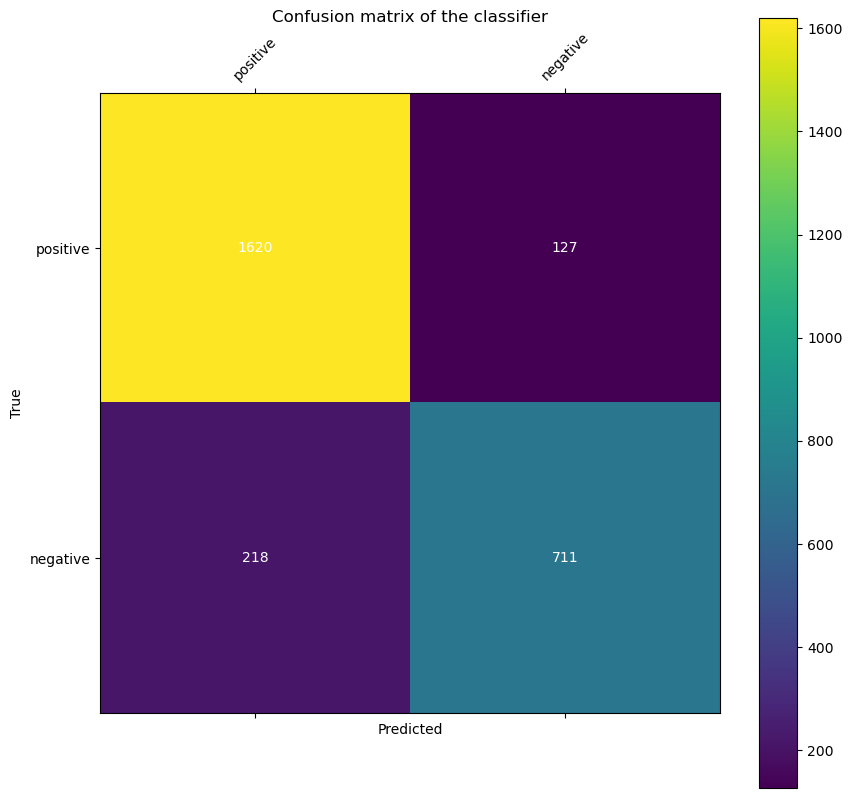

Error analysis results saved to 'false_positives.txt' and 'false_negatives.txt'


In [16]:
# Capture data needed for error analysis
avg_results, true_labels, predicted_labels, last_test_data = cross_validate(train_data, 10, perform_error_analysis=True)

# Call error_analysis separately using the last fold's data
error_analysis(last_test_data, true_labels, predicted_labels)

## My solution to analyze the error .txts

In [ ]:
from collections import Counter
import re
# function to analyze word frequencies in false positives and false negatives .txts
def analyze_error_words(false_positive_path, false_negative_path):
    def load_and_tokenize(file_path):
        #load the file and extract tokens 
        tokens = []
        with open(file_path, 'r') as file:
            lines = file.readlines()[1:]  # skipping the header

            for line in lines:
                # using token frequency and Counter
                match = re.findall(r"'(\w+)':\s(\d+)", line.lower())  
                for token, count in match:
                    tokens.extend([token] * int(count)) 

        return tokens

    # get word frequencies
    false_positive_words = Counter(load_and_tokenize(false_positive_path))
    false_negative_words = Counter(load_and_tokenize(false_negative_path))

    # print the 10 most common words
    print("Most common words in false positives:")
    for word, count in false_positive_words.most_common(30):
        print(f"{word}: {count}")

    print("\nMost common words in false negatives:")
    for word, count in false_negative_words.most_common(30):
        print(f"{word}: {count}")

false_positive_path = "false_positives.txt"
false_negative_path = "false_negatives.txt"

# calling the func
analyze_error_words(false_positive_path, false_negative_path)


Most common words in false positives:
the: 172
to: 99
a: 82
i: 79
and: 63
on: 62
it: 61
of: 58
in: 48
is: 46
for: 39
you: 35
be: 33
tomorrow: 32
may: 32
this: 29
just: 29
with: 28
have: 28
but: 26
day: 25
th: 24
wa: 22
im: 22
my: 22
up: 21
at: 21
will: 18
we: 18
game: 18

Most common words in false negatives:
the: 106
i: 58
a: 55
to: 43
on: 40
is: 39
it: 34
of: 31
and: 30
in: 29
for: 29
be: 27
my: 24
may: 22
that: 21
but: 21
not: 20
tomorrow: 19
he: 18
im: 16
with: 16
wa: 15
you: 14
th: 14
they: 12
in_the: 12
like: 12
all: 12
see: 12
have: 12


# Part 5: Optimising pre-processing and feature extraction

In [18]:
# Finally, check the accuracy of your classifier by training on all the traning data
# and testing on the test set
# Will only work once all functions are complete
functions_complete = True  # set to True once you're happy with your methods for cross val
if functions_complete:
    print(test_data[0])   # have a look at the first test data instance
    classifier = train_classifier(train_data)  # train the classifier
    test_true = [t[1] for t in test_data]   # get the ground-truth labels from the data
    test_pred = predict_labels([x[0] for x in test_data], classifier)  # classify the test data to get predicted labels
    final_scores = precision_recall_fscore_support(test_true, test_pred, average='weighted') # evaluate
    print("Done training!")
    print("Precision: %f\nRecall: %f\nF Score:%f" % final_scores[:3])

(Counter({'well': 2, 'our': 2, 'tomorrow': 1, 'release': 1, 'th': 1, 'episode': 1, 'of': 1, 'hsonair': 1, 'profiling': 1, 'very': 1, 'own': 1, 'alissadossantos': 1, 'talk': 1, 'about': 1, 'storytelling': 1, 'and': 1, 'beyonce': 1, 'tomorrow_well': 1, 'well_release': 1, 'release_our': 1, 'our_th': 1, 'th_episode': 1, 'episode_of': 1, 'of_hsonair': 1, 'hsonair_profiling': 1, 'profiling_our': 1, 'our_very': 1, 'very_own': 1, 'own_alissadossantos': 1, 'alissadossantos_well': 1, 'well_talk': 1, 'talk_about': 1, 'about_storytelling': 1, 'storytelling_and': 1, 'and_beyonce': 1}), 'positive')
Training Classifier...


Done training!
Precision: 0.864245
Recall: 0.865534
F Score:0.864375
